# Bayesian Inference with Spectral Constraints: CTCV J2056-3014

This notebook extends the analysis from `07_bayesian_inference.ipynb` by incorporating X-ray spectral constraints ($L_X$ and $kT_{\text{max}}$) directly into the likelihood. This addresses the M–$\dot{M}$ prior correlation from spectral fitting (Salcedo+2024) by replacing informative spectral mass priors with broad population priors, and letting the spectral observables constrain the parameters through the physics.

**Data sources:**
- $\dot{P}_{\rm obs} = 0.0 \pm 1.7 \times 10^{-15}$ s/s (Salcedo+2024, Section 3.3)
- $L_X = 1.8 \times 10^{31}$ erg/s (0.3–12 keV, low state; Salcedo+2024)
- $kT_{\rm max} = 16.3^{+1.9}_{-1.8}$ keV (MKCFLOW; Salcedo+2024, Table 6)

## Analysis Overview

### Motivation

CTCV J2056-3014 (hereafter CJ2056) is a cataclysmic variable with a 29.6 s white-dwarf spin period. A previous analysis (notebook `07`) used $\dot{P}$ alone to compare an intermediate polar (IP) model against a non-magnetic CV (nmCV) model. That analysis relied on **informative mass priors derived from X-ray spectral fits** (Salcedo+2024), which introduced a correlation between $M_{\rm WD}$ and $\dot{M}$ before the inference even began.

- Because the spectral-fit mass priors already encoded information from the same $L_X$ and $kT$ data we want to use as constraints, using those priors here would amount to double-counting. We therefore replace them with **broad, population-based priors** and let the spectral observables enter through the likelihood instead.
- This notebook extends the model to **three observables** ($\dot{P}$, $kT_{\rm max}$, $L_X$), which jointly constrain the WD mass, accretion rate, and (for the IP) the magnetic dipole moment.

### Goal

Perform a Bayesian model comparison between two accretion scenarios for CJ2056:

- **nmCV (non-magnetic CV):** Disk extends to WD surface. 2 free parameters.
- **IP (intermediate polar):** Disk truncated at the magnetospheric radius $r_m$. 4 free parameters.

We quantify the relative evidence for each model via the Bayes factor, constrain physical parameters under each model, and assess what the new precise $\dot{P}$ measurement adds beyond spectral data.

---

### Observational Data

All measurements from Salcedo+2024 unless otherwise noted.

| Observable | Value | Uncertainty ($1\sigma$) | Source / Notes |
|:---|:---|:---|:---|
| $P$ (spin period) | 29.609685843 s | — | High-precision timing |
| $\dot{P}_{\rm obs}$ | 0.0 s/s | $1.7 \times 10^{-15}$ s/s | Salcedo+2024 Section 3.3; null detection |
| $d$ (distance) | 261.6 pc | 7.4 pc | Gaia parallax |
| $F_X$ (unabsorbed flux, 0.3–12 keV) | $2.2 \times 10^{-12}$ erg s$^{-1}$ cm$^{-2}$ | 5% (spectral fit stat. error) | Salcedo+2024 |
| $L_X$ (derived, $4\pi d^2 F_X$) | $1.8 \times 10^{31}$ erg/s | 7.6% ($\approx 1.4\times10^{30}$ erg/s) | Propagated from $d$ and $F_X$: $\sigma_{L_X}/L_X = \sqrt{(2\sigma_d/d)^2 + \sigma_{F_X}^2}$ |
| $kT_{\rm max}$ (MKCFLOW) | 16.3 keV | 1.15 keV | 90% CI (+1.9/−1.8 keV) $\to$ $1\sigma$ via $\div 1.645$ |

---

### Physical Constants and Auxiliary Quantities

| Symbol | Value | Units | Notes |
|:---|:---|:---|:---|
| $G$ | $6.674 \times 10^{-8}$ | cm$^3$ g$^{-1}$ s$^{-2}$ | Gravitational constant |
| $M_\odot$ | $1.989 \times 10^{33}$ | g | Solar mass |
| $R_\odot$ | $6.957 \times 10^{10}$ | cm | Solar radius |
| $m_H$ | $1.6726 \times 10^{-24}$ | g | Proton mass |
| $\mu_{\rm mol}$ | 0.617 | — | Mean molecular weight, fully ionized solar composition |
| $\alpha_{\rm Yu}$ | 0.646 | — | Empirical shock-temperature correction (Yu+2018; calibrated on 11 nmCVs) |
| $R(M)$, $I(M)$ | Tabulated | cm, g cm$^2$ | Zero-temperature, C-12 WD mass–radius–inertia relation; cubic interpolation. Range: $\sim$0.01–0.99 $M_\odot$ |

---

### Forward Models

Because CJ2056 shows hard thermal X-ray emission ($kT \approx 16$ keV), which requires a standing accretion shock on the WD surface, **we restrict the IP model to the accretion regime** ($r_m \in [R_{\rm WD},\, r_{\rm co}]$). Parameter combinations that place the magnetosphere outside this range (propeller or buried-field) are rejected by the forward models (return NaN $\to$ $\ln\mathcal{L} = -10^{100}$).

**$\dot{P}$ models** (Bhattacharyya & Chakrabarty 2017):
- The spin-evolution equation is $\dot{P}_{\rm pred} = -P^2 \tau / (2\pi I)$, where $\tau$ is the net torque.
- *nmCV:* $\tau = \dot{M}\sqrt{GM R_{\rm WD}}$ — pure spin-up from disk angular momentum deposited at the WD surface.
- *IP (accretion branch, Eq. 9):* $\tau = \tau_{\rm acc} + \tau_{\rm mag}$, where
  - $\tau_{\rm acc} = \dot{M}\sqrt{GM r_m}$ (accretion spin-up)
  - $\tau_{\rm mag} = \frac{\mu^2}{9 r_m^3}\left(2x^3 - 6x^{3/2} + 3\right)$, $x \equiv r_m / r_{\rm co}$ (magnetic threading; can spin up or down depending on $x$)
  - $r_m = \xi \left(\frac{\mu^4}{2GM\dot{M}^2}\right)^{1/7}$ (magnetospheric radius, Ghosh & Lamb 1979)
  - $r_{\rm co} = \left(\frac{GMP^2}{4\pi^2}\right)^{1/3}$ (corotation radius)

**Spectral forward models:**
- *nmCV:* Boundary-layer shock temperature with empirical calibration:
  - $kT_{\rm pred} = \frac{3}{16}\,\alpha_{\rm Yu}\,\mu_{\rm mol}\,m_H\,\frac{GM}{R}$ (Yu+2018)
  - $L_{X,\rm pred} = f_{\rm band}(kT_{\rm pred}) \cdot \frac{GM\dot{M}}{R}$
- *IP:* Rankine-Hugoniot strong-shock maximum ($\gamma = 5/3$), free-fall from $r_m$ to $R_{\rm WD}$:
  - $kT_{\rm pred} = \frac{3}{16}\,\mu_{\rm mol}\,m_H\,v_{\rm ff}^2$, where $v_{\rm ff}^2 = 2GM\left(\frac{1}{R} - \frac{1}{r_m}\right)$
  - $L_{X,\rm pred} = f_{\rm band}(kT_{\rm pred}) \cdot GM\dot{M}\left(\frac{1}{R} - \frac{1}{r_m}\right)$
- The band-correction factor $f_{\rm band}(kT) = e^{-E_{\rm lo}/kT} - e^{-E_{\rm hi}/kT}$ converts bolometric to 0.3–12 keV, assuming single-temperature optically thin bremsstrahlung with Gaunt factor $g_{\rm ff} \approx 1$.

**Key modelling choices and their justifications:**
- *No $\alpha_{\rm Yu}$ correction for the IP:* The Yu+2018 calibration is specific to boundary-layer shocks in nmCVs. IPs form magnetically channeled accretion columns with different shock geometry, so the unadjusted Rankine-Hugoniot result is used.
- *No propeller regime:* The observed hard X-ray emission requires an accretion shock. Propeller systems eject material at $r_m$ and do not produce standing shocks on the WD surface. We therefore exclude the propeller branch a priori.
- *Single-temperature $f_{\rm band}$:* The real post-shock column is multi-temperature (MKCFLOW models a cooling flow), so this introduces a $\sim$20–30% systematic in $L_{X,\rm pred}$. This is a standard approximation; the systematic is absorbed into the $\dot{M}$ posterior.

---

### Prior Specification

We chose **population-based, physics-independent priors** to avoid circular reasoning (the spectral data enter only through the likelihood, not the prior).

| Parameter | Symbol | nmCV prior | IP prior | Justification |
|:---|:---|:---|:---|:---|
| WD mass | $M_{\rm WD}$ ($M_\odot$) | $\mathcal{N}(0.83,\, 0.20)$, clipped to table range | same | Pala+2022 volume-limited CV sample mean and dispersion |
| Log accretion rate | $\log_{10}\dot{M}$ (g/s) | $\mathcal{U}(13,\, 17)$ | same | Broad, uninformative; spans dwarf novae ($\sim10^{13}$) to nova-like ($\sim10^{17}$) |
| Log magnetic moment | $\log_{10}\mu$ (G cm$^3$) | — | $\mathcal{U}(29,\, 35)$ | Covers the full observed IP range ($\sim10^{29}$–$10^{34}$), conservative |
| Magnetospheric prefactor | $\xi$ | — | log-$\mathcal{U}(0.3,\, 1.0)$ | Ghosh & Lamb (1979) disk-accretion range; log-uniform ensures geometric centering of the $\xi^{-7/4}$ systematic on $B$ |

- The Gaussian mass prior is clipped to $[M_{\rm min,table} + 0.001,\; M_{\rm max,table} - 0.001]$ to avoid cubic-interpolation edge effects on $R(M)$ and $I(M)$.
- **Derived quantity:** The surface magnetic field $B = \mu / R^3$ is not a sampled parameter but is computed from the posterior samples of $M_{\rm WD}$ (which determines $R$) and $\mu$.

---

### Likelihood

All three observables are treated as **independent Gaussians**:

$$\ln\mathcal{L} = -\frac{1}{2}\left[\left(\frac{\dot{P}_{\rm obs} - \dot{P}_{\rm pred}}{\sigma_{\dot{P}}}\right)^2 + \left(\frac{kT_{\rm obs} - kT_{\rm pred}}{\sigma_{kT}}\right)^2 + \left(\frac{L_{X,\rm obs} - L_{X,\rm pred}}{\sigma_{L_X}}\right)^2\right]$$

- Samples outside the accretion range ($r_m \notin [R_{\rm WD}, r_{\rm co}]$) or with unphysical predictions ($kT \le 0$, $L_X \le 0$, NaN) receive $\ln\mathcal{L} = -10^{100}$.
- **Independence assumption:** $kT$ and $L_X$ come from the same MKCFLOW spectral fit and share correlated systematics (e.g., $N_H$). We do not propagate this covariance. This likely makes the posterior slightly too narrow but affects both models symmetrically.

---

### Inference Engine

| Setting | Value | Notes |
|:---|:---|:---|
| Algorithm | `dynesty.DynamicNestedSampler` | Dynamic nested sampling; adaptively allocates live points for evidence accuracy |
| $n_{\rm live}$ | 2000 | Conservative for 2D and 4D problems; ensures stable $\ln Z$ |
| Bounding | `'multi'` | Multi-ellipsoid decomposition |
| Sampling | `'rwalk'` | Random-walk proposal; efficient for low-dimensional posteriors |
| Random seed | `np.random.Generator(PCG64(seed))` | Seeds 42–47 for the six sampler runs, for reproducibility |

- **Model evidence** $\ln Z$ and its numerical uncertainty $\sigma_{\ln Z}$ are extracted from `results['logz'][-1]` and `results['logzerr'][-1]`.
- **Equal-weight posterior samples** are obtained via `dynesty.utils.resample_equal`.

---

### Model Comparison

- The **Bayes factor** $\mathcal{B}_{\rm IP/nmCV} = Z_{\rm IP} / Z_{\rm nmCV}$ is computed as $\ln\mathcal{B} = \ln Z_{\rm IP} - \ln Z_{\rm nmCV}$.
- Uncertainty: $\sigma_{\ln\mathcal{B}} = \sqrt{\sigma_{\ln Z_{\rm IP}}^2 + \sigma_{\ln Z_{\rm nmCV}}^2}$.
- Interpretation follows the **Jeffreys (1961) scale**: $|\ln\mathcal{B}| < 1$ = "not worth more than a bare mention"; $1$–$2.5$ = "substantial"; $2.5$–$5$ = "strong"; $> 5$ = "decisive".
- Note: The IP model has 2 extra parameters ($\log_{10}\mu$, $\xi$), so the Bayes factor includes an intrinsic **Occam penalty** proportional to the unused prior volume. With a 6-dex $\mu$ prior, this penalty is non-trivial.

---

### Analysis Steps

1. **Main inference (Cells 9–14):** Run nested sampling for both IP (4D) and nmCV (2D). Extract posteriors, compute Bayes factor.

2. **Corner plots with prior overlays (Cells 16–17):** Visualize the posterior in both a prior-range view (to see how much the data have constrained relative to the prior) and a posterior-zoom view (to resolve the posterior structure). Prior PDFs overlaid on the 1D marginals.

3. **Predicted $\dot{P}$ distribution (Cell 19):** For each posterior sample, compute the model-predicted $\dot{P}$ and compare to the observed $\dot{P} = 0 \pm 1.7\times10^{-15}$. This checks internal consistency: does the spectral-constrained posterior predict a $\dot{P}$ compatible with the timing measurement?

4. **Posterior predictive check (Cell 21):** Compute predicted $kT$ and $L_X$ from the posterior and compare to observations. Reports per-observable $\chi^2$ contributions to verify the models reproduce the input data.

5. **Spin-equilibrium diagnostics (Cells 22–23):**
   - $r_m / r_{\rm co}$ posterior: values near 1 indicate the system is close to spin equilibrium (accretion and magnetic torques nearly cancel).
   - Spin-evolution timescale $\tau = P / |\dot{P}|$: if $\tau \gg$ Gyr, the spin period is effectively frozen — consistent with long-term equilibrium expected for evolved disk-fed IPs.

6. **Sensitivity: old vs. new $\dot{P}$ constraint (Cells 25–28):** Re-run the full inference with the old, weak constraint ($\sigma_{\dot{P}} = 1.8 \times 10^{-12}$ s/s, effectively no timing information). Comparing posteriors and Bayes factors isolates the impact of the improved timing precision.

7. **Sensitivity: spectral-only leverage check (Cells 30–31):** Re-run with $\dot{P}$ removed entirely from the likelihood ($kT + L_X$ only). If the posteriors are unchanged, then $\dot{P}$ is a consistency check, not a constraint — the spectral data already pin the system near spin equilibrium where $\dot{P} \approx 0$.

---

### Caveats

- **$f_{\rm band}$ approximation:** Single-temperature bremsstrahlung; real spectra are multi-temperature cooling flows. Introduces $\sim$20–30% systematic on $L_{X,\rm pred}$.
- **$\alpha_{\rm Yu}$ uncertainty:** Calibrated on only 11 nmCVs (Yu+2018). The nmCV $kT$ prediction and thus the $M_{\rm WD}$ constraint depend directly on this value.
- **Flux uncertainty (5%):** Statistical only; systematic errors from absorption, spectral model choice, and calibration could be 15–30%.
- **$L_X$–$kT$ independence:** Correlated measurement systematics are not propagated.
- **IP prior volume:** The 6-dex $\log_{10}\mu$ prior inflates the Occam penalty against the IP model. A narrower, physically motivated range would reduce this penalty.


In [75]:
import numpy as np
from scipy.interpolate import interp1d
from scipy.stats import norm
import matplotlib.pyplot as plt
import corner
import dynesty
from dynesty import utils as dyfunc
from dynesty import plotting as dyplot

plt.rcParams.update({
    'font.size': 13,
    'axes.labelsize': 13,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'figure.constrained_layout.use': True,
})

savedir = '../paper_figures' 

## Constants, Data, and WD Mass-Radius-Inertia Relation

In [76]:
# --- Physical constants (CGS) ---
G = 6.674e-8       # cm^3 g^-1 s^-2
Msun = 1.989e33    # g
Rsun = 6.957e10    # cm
m_H = 1.6726e-24   # proton mass [g]
keV_to_erg = 1.602e-9  # keV -> erg

# --- Measured timing data (1-sigma) ---
P = 29.609685843       # spin period [s]
Pdot_obs = 0.0         # observed Pdot [s/s]
sigma_Pdot = 1.7e-15   # 1-sigma uncertainty on Pdot [s/s]

# --- Spectral observables (Salcedo+2024) ---
# X-ray luminosity: F_X(unabs, 0.3-12 keV) = 2.2e-12 erg/s/cm^2, d = 261.6 +/- 7.4 pc
d_pc = 261.6                           # distance [pc]
sigma_d_pc = 7.4                       # 1-sigma distance error [pc]
d_cm = d_pc * 3.086e18                 # distance [cm]
F_X = 2.2e-12                          # unabsorbed flux [erg/s/cm^2]
sigma_FX_frac = 0.05                   # ~5% flux uncertainty (spectral fit)
L_X_obs = 4 * np.pi * d_cm**2 * F_X   # X-ray luminosity [erg/s], 0.3-12 keV band
# Propagate distance + flux uncertainties
sigma_LX = L_X_obs * np.sqrt((2 * sigma_d_pc / d_pc)**2 + sigma_FX_frac**2)

# X-ray band for the bolometric -> band-limited correction applied to L_X_pred
LX_BAND_LO = 0.3   # keV
LX_BAND_HI = 12.0  # keV

# kT_max from MKCFLOW (Salcedo+2024, Table 6)
# 90% CI: 16.3 +1.9/-1.8 keV -> 1-sigma ~ 1.9/1.645 ~ 1.15 keV
kT_obs = 16.3        # keV
sigma_kT = 1.15       # 1-sigma [keV]

# Mean molecular weight for fully ionized solar-composition plasma
mu_mol = 0.617
# Empirical correction factor (Yu+2018, calibrated on 11 nmCVs)
alpha_Yu = 0.646

# --- Load WD mass-radius-inertia table ---
mr_data = np.loadtxt('../wd_mass_radius/mass_radius.txt', delimiter=',', skiprows=1)
M_table = mr_data[:, 0]   # M_sun
R_table = mr_data[:, 1]   # R_sun
I_table = mr_data[:, 2]   # g cm^2

# Interpolators: input in solar masses, output in CGS
get_R = interp1d(M_table, R_table * Rsun, kind='cubic')   # returns cm
get_I = interp1d(M_table, I_table, kind='cubic')           # returns g cm^2

M_min_table = M_table.min()
M_max_table = M_table.max()

# --- Magnetosphere geometry ---
# xi: magnetospheric-radius prefactor, r_m = xi * r_Alfven (Ghosh & Lamb 1979).
#     Conventional disk-accretion value is ~0.5, literature range ~0.3-1.
#     Since r_m ~ B^(4/7), the inferred B scales as xi^(-7/4); a factor-2
#     uncertainty in xi maps to ~3.4x on B. We marginalise over xi as a
#     sampled nuisance parameter so the B posterior reflects this systematic.

print(f"Table range: {M_min_table:.3f} - {M_max_table:.3f} Msun")
print(f"L_X_obs = {L_X_obs:.2e} erg/s  (sigma = {sigma_LX:.2e})")
print(f"kT_obs  = {kT_obs:.1f} +/- {sigma_kT:.2f} keV (1-sigma)")


Table range: 0.010 - 1.406 Msun
L_X_obs = 1.80e+31 erg/s  (sigma = 1.36e+30)
kT_obs  = 16.3 +/- 1.15 keV (1-sigma)


## Forward Models

We model CJ2056 as an **accreting intermediate polar**. The observed hard thermal X-ray emission ($kT \approx 16$ keV, $L_X \approx 10^{31}$ erg/s) is an accretion-shock signature, so we restrict the IP model to $r_m \in [R_{\rm WD}, r_{\rm co}]$ (no propeller regime) throughout.

**Pdot** follows Bhattacharyya & Chakrabarty (2017, Eq. 9) in the accretion regime.

**Spectral forward models:**

*nmCV:*
- $kT_{\text{pred}} = \frac{3}{16} \alpha \mu_{\text{mol}} m_H \frac{GM}{R}$ (Yu+2018, $\alpha = 0.646$)
- $L_{X,\text{pred}} = f_{\rm band}(kT_{\rm pred}) \cdot \frac{GM\dot{M}}{R}$

*IP:*
- $kT_{\text{pred}} = \frac{3}{16} \mu_{\text{mol}} m_H \cdot 2GM\left(\frac{1}{R} - \frac{1}{r_m}\right)$ (Rankine-Hugoniot strong shock, $\gamma = 5/3$)
- $L_{X,\text{pred}} = f_{\rm band}(kT_{\rm pred}) \cdot GM\dot{M}\left(\frac{1}{R} - \frac{1}{r_m}\right)$

Samples with $r_m \le R_{\rm WD}$ or $r_m > r_{\rm co}$ are rejected by the likelihood (forward models return NaN).

**Band correction.** Theoretical accretion luminosities are bolometric, whereas $L_{X,\rm obs}$ is the unabsorbed flux in 0.3-12 keV. For single-temperature thermal bremsstrahlung with Gaunt factor $g_{\rm ff} \approx 1$,
$$f_{\rm band}(kT) = \exp(-E_{\rm lo}/kT) - \exp(-E_{\rm hi}/kT),$$
evaluated at the predicted $kT$. At $kT \sim 16$ keV this gives $f_{\rm band} \approx 0.5$.


In [77]:
# =====================================================
# Pdot forward models (Bhattacharyya & Chakrabarty 2017)
# =====================================================

def pdot_nmcv(M_wd_solar, log10_Mdot):
    """Predicted Pdot for the nmCV case (disk extends to WD surface, spin-up only)."""
    M = M_wd_solar * Msun
    Mdot = 10**log10_Mdot
    R = get_R(M_wd_solar)
    I = get_I(M_wd_solar)
    tau = Mdot * np.sqrt(G * M * R)
    return -P**2 * tau / (2 * np.pi * I)


def pdot_ip(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Predicted Pdot for an accreting IP (r_m in [R_WD, r_co]).

    Bhattacharyya & Chakrabarty (2017, Eq. 9). Returns NaN outside the accretion
    range (r_m <= R_WD or r_m > r_co).
    """
    M = M_wd_solar * Msun
    Mdot = 10**log10_Mdot
    mu = 10**log10_mu
    R = get_R(M_wd_solar)
    I = get_I(M_wd_solar)

    r_m = xi * (mu**4 / (2 * G * M * Mdot**2))**(1.0/7.0)
    r_co = (G * M * P**2 / (4 * np.pi**2))**(1.0/3.0)

    if r_m <= R or r_m > r_co:
        return np.nan

    x = r_m / r_co
    tau_acc = Mdot * np.sqrt(G * M * r_m)
    tau_mag = mu**2 / (9 * r_m**3) * (2 * x**3 - 6 * x**1.5 + 3)
    return -P**2 * (tau_acc + tau_mag) / (2 * np.pi * I)


# =====================================================
# Band-correction factor for the bolometric -> 0.3-12 keV conversion
# =====================================================

def f_band(kT_keV):
    """Fraction of bolometric thermal-bremsstrahlung luminosity in LX_BAND_LO..LX_BAND_HI.

    Single-temperature bremsstrahlung with Gaunt factor ~1:
        dL/dE ~ exp(-E/kT)  ->  L(E1,E2)/L_bol = exp(-E1/kT) - exp(-E2/kT).
    """
    return np.exp(-LX_BAND_LO / kT_keV) - np.exp(-LX_BAND_HI / kT_keV)


# =====================================================
# Spectral forward models
# =====================================================

def kT_nmcv(M_wd_solar):
    """Predicted maximum shock temperature for nmCV [keV] (Yu+2018 relation)."""
    M = M_wd_solar * Msun
    R = get_R(M_wd_solar)
    kT_erg = (3.0 / 16.0) * alpha_Yu * mu_mol * m_H * G * M / R
    return kT_erg / keV_to_erg


def LX_nmcv(M_wd_solar, log10_Mdot):
    """Predicted 0.3-12 keV X-ray luminosity for nmCV [erg/s]."""
    M = M_wd_solar * Msun
    R = get_R(M_wd_solar)
    Mdot = 10**log10_Mdot
    L_bol = G * M * Mdot / R
    return f_band(kT_nmcv(M_wd_solar)) * L_bol


def kT_ip(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Predicted shock temperature for an accreting IP [keV].

    Returns NaN outside the accretion range (r_m <= R_WD or r_m > r_co).
    """
    M = M_wd_solar * Msun
    R = get_R(M_wd_solar)
    Mdot = 10**log10_Mdot
    mu = 10**log10_mu
    r_m = xi * (mu**4 / (2 * G * M * Mdot**2))**(1.0/7.0)
    r_co = (G * M * P**2 / (4 * np.pi**2))**(1.0/3.0)
    if r_m <= R or r_m > r_co:
        return np.nan
    vff2 = 2 * G * M * (1.0 / R - 1.0 / r_m)
    kT_erg = (3.0 / 16.0) * mu_mol * m_H * vff2
    return kT_erg / keV_to_erg


def LX_ip(M_wd_solar, log10_Mdot, log10_mu, xi):
    """Predicted 0.3-12 keV X-ray luminosity for an accreting IP [erg/s]."""
    M = M_wd_solar * Msun
    R = get_R(M_wd_solar)
    Mdot = 10**log10_Mdot
    mu = 10**log10_mu
    r_m = xi * (mu**4 / (2 * G * M * Mdot**2))**(1.0/7.0)
    r_co = (G * M * P**2 / (4 * np.pi**2))**(1.0/3.0)
    if r_m <= R or r_m > r_co:
        return np.nan
    vff2 = 2 * G * M * (1.0 / R - 1.0 / r_m)
    kT = (3.0 / 16.0) * mu_mol * m_H * vff2 / keV_to_erg
    L_bol = G * M * Mdot * (1.0 / R - 1.0 / r_m)
    return f_band(kT) * L_bol


# --- Sanity checks ---
print("=== Pdot checks ===")
print(f"nmCV(0.935, 15): Pdot = {pdot_nmcv(0.935, 15):.3e}")
print(f"IP(0.815, 15, 30.3, xi=0.5): Pdot = {pdot_ip(0.815, 15, 30.3, 0.5):.3e}")

print("\n=== f_band checks ===")
print(f"f_band(16.3 keV): {f_band(16.3):.3f}   (0.3-12 keV fraction at kT_obs)")
print(f"f_band(10 keV):   {f_band(10.0):.3f}")
print(f"f_band(30 keV):   {f_band(30.0):.3f}")

print("\n=== kT checks ===")
print(f"nmCV kT(0.9): {kT_nmcv(0.9):.1f} keV  (expect ~15-20 keV)")
print(f"IP kT(0.8, 14.5, 30.0, 0.5): {kT_ip(0.8, 14.5, 30.0, 0.5):.1f} keV")

print("\n=== L_X checks (band-corrected) ===")
print(f"nmCV L_X(0.9, 14.5): {LX_nmcv(0.9, 14.5):.2e} erg/s")
print(f"IP L_X(0.8, 14.5, 30.0, 0.5): {LX_ip(0.8, 14.5, 30.0, 0.5):.2e} erg/s")


=== Pdot checks ===
nmCV(0.935, 15): Pdot = -2.381e-16
IP(0.815, 15, 30.3, xi=0.5): Pdot = -3.262e-16

=== f_band checks ===
f_band(16.3 keV): 0.503   (0.3-12 keV fraction at kT_obs)
f_band(10 keV):   0.669
f_band(30 keV):   0.320

=== kT checks ===
nmCV kT(0.9): 15.7 keV  (expect ~15-20 keV)
IP kT(0.8, 14.5, 30.0, 0.5): 8.9 keV

=== L_X checks (band-corrected) ===
nmCV L_X(0.9, 14.5): 3.28e+31 erg/s
IP L_X(0.8, 14.5, 30.0, 0.5): 8.26e+30 erg/s


## Priors and Likelihood

**Priors (nmCV, 2D):**
- $M_{\rm WD}$: $\mathcal{N}(0.83, 0.20)$ (Pala+2022, volume-limited CV sample), clipped to WD table range
- $\log_{10}\dot{M}$: $\mathcal{U}(13, 17)$ (flat in log-space)

**Priors (IP, 4D):**
- $M_{\rm WD}$: $\mathcal{N}(0.83, 0.20)$ clipped to table range
- $\log_{10}\dot{M}$: $\mathcal{U}(13, 17)$
- $\log_{10}\mu$: $\mathcal{U}(29, 35)$ (magnetic dipole moment, G$\,$cm$^3$)
- $\xi$: log-uniform on $[0.3, 1.0]$ (magnetospheric-radius prefactor; Ghosh & Lamb 1979 range)

Sampling $\xi$ marginalises the factor-$\xi^{-7/4}$ systematic in $B$ into the posterior rather than fixing it at a conventional value.

**Likelihood.** All three observables ($\dot P$, $kT$, $L_X$) enter as independent Gaussians:
$$\ln\mathcal{L} = -\tfrac12\!\left[\left(\tfrac{\dot P_{\rm obs} - \dot P_{\rm pred}}{\sigma_{\dot P}}\right)^2 + \left(\tfrac{kT_{\rm obs} - kT_{\rm pred}}{\sigma_{kT}}\right)^2 + \left(\tfrac{L_{X,\rm obs} - L_{X,\rm pred}}{\sigma_{L_X}}\right)^2\right].$$

The IP forward models return NaN outside the accretion range ($r_m \in [R_{\rm WD}, r_{\rm co}]$); those samples are rejected ($\ln\mathcal{L} = -10^{100}$).


In [78]:
# =====================================================
# nmCV model: 2 parameters [M_wd, log10_Mdot]
# =====================================================

# Population mass prior (Pala+2022)
POP_M_MU, POP_M_SIG = 0.83, 0.20

# log10(Mdot) flat prior
LOGMDOT_LO, LOGMDOT_HI = 13.0, 17.0


def prior_transform_nmcv(u):
    """Map unit cube [0,1]^2 -> nmCV parameter space."""
    theta = np.empty(2)
    theta[0] = norm.ppf(u[0], loc=POP_M_MU, scale=POP_M_SIG)
    theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
    theta[1] = LOGMDOT_LO + u[1] * (LOGMDOT_HI - LOGMDOT_LO)
    return theta


def log_likelihood_nmcv(theta):
    """Log-likelihood for nmCV model with Pdot + L_X + kT."""
    M_wd, log_Mdot = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100

    Pdot_pred = pdot_nmcv(M_wd, log_Mdot)
    kT_pred = kT_nmcv(M_wd)
    LX_pred = LX_nmcv(M_wd, log_Mdot)

    chi2  = ((Pdot_obs - Pdot_pred) / sigma_Pdot)**2
    chi2 += ((kT_obs - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    return -0.5 * chi2


# =====================================================
# IP model: 4 parameters [M_wd, log10_Mdot, log10_mu, xi]  (accreting only)
# =====================================================

LOGMU_LO, LOGMU_HI = 29.0, 35.0
XI_LO, XI_HI = 0.3, 1.0  # log-uniform prior range (Ghosh & Lamb 1979)


def prior_transform_ip(u):
    """Map unit cube [0,1]^4 -> IP parameter space."""
    theta = np.empty(4)
    theta[0] = norm.ppf(u[0], loc=POP_M_MU, scale=POP_M_SIG)
    theta[0] = np.clip(theta[0], M_min_table + 0.001, M_max_table - 0.001)
    theta[1] = LOGMDOT_LO + u[1] * (LOGMDOT_HI - LOGMDOT_LO)
    theta[2] = LOGMU_LO + u[2] * (LOGMU_HI - LOGMU_LO)
    theta[3] = 10**(np.log10(XI_LO) + u[3] * (np.log10(XI_HI) - np.log10(XI_LO)))
    return theta


def log_likelihood_ip(theta):
    """Accreting-IP log-likelihood. Samples with r_m outside [R_WD, r_co]
    yield NaN from the forward models and are rejected."""
    M_wd, log_Mdot, log_mu, xi_s = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100

    Pdot_pred = pdot_ip(M_wd, log_Mdot, log_mu, xi_s)
    kT_pred   = kT_ip (M_wd, log_Mdot, log_mu, xi_s)
    LX_pred   = LX_ip (M_wd, log_Mdot, log_mu, xi_s)
    if (np.isnan(Pdot_pred) or np.isnan(kT_pred) or np.isnan(LX_pred)
            or kT_pred <= 0 or LX_pred <= 0):
        return -1e100

    chi2  = ((Pdot_obs - Pdot_pred) / sigma_Pdot)**2
    chi2 += ((kT_obs  - kT_pred)    / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred)    / sigma_LX)**2
    return -0.5 * chi2


# --- Quick check ---
print(f"log L(IP, accretion):  {log_likelihood_ip([0.8, 14.5, 30.0, 0.5]):.3e}")
print(f"log L(IP, propeller rejected): {log_likelihood_ip([0.8, 14.0, 33.0, 0.5]):.3e}")


log L(IP, accretion):  -4.614e+01
log L(IP, propeller rejected): -1.000e+100


## Nested Sampling

In [79]:
print("Running IP nested sampling (4 params: M_WD, log Mdot, log mu, xi)...")
sampler_ip = dynesty.DynamicNestedSampler(
    log_likelihood_ip, prior_transform_ip, ndim=4,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(42))
)
sampler_ip.run_nested(print_progress=True)
results_ip = sampler_ip.results
print(f"IP done: logZ = {results_ip['logz'][-1]:.2f} +/- {results_ip['logzerr'][-1]:.2f}")


Running IP nested sampling (4 params: M_WD, log Mdot, log mu, xi)...


30855it [01:33, 331.44it/s, batch: 1 | bound: 2 | nc: 1 | ncall: 645486 | eff(%):  4.462 | loglstar: -1.907 < -0.004 < -0.520 | logz: -8.919 +/-  0.065 | stop:  0.738]                       

IP done: logZ = -8.92 +/- 0.05


In [80]:
print("Running nmCV nested sampling (2 params, with L_X + kT constraints)...")
sampler_nmcv = dynesty.DynamicNestedSampler(
    log_likelihood_nmcv, prior_transform_nmcv, ndim=2,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(43))
)
sampler_nmcv.run_nested(print_progress=True)
results_nmcv = sampler_nmcv.results
print(f"nmCV done: logZ = {results_nmcv['logz'][-1]:.2f} +/- {results_nmcv['logzerr'][-1]:.2f}")


Running nmCV nested sampling (2 params, with L_X + kT constraints)...


27495it [01:10, 392.56it/s, batch: 1 | bound: 2 | nc: 1 | ncall: 434979 | eff(%):  5.764 | loglstar: -1.837 < -0.000 < -0.486 | logz: -5.761 +/-  0.051 | stop:  0.743]                    


nmCV done: logZ = -5.77 +/- 0.04


## Results

In [81]:
# --- Extract equal-weight posterior samples ---

# IP
weights_ip = np.exp(results_ip['logwt'] - results_ip['logz'][-1])
weights_ip /= weights_ip.sum()
samples_ip_eq = dyfunc.resample_equal(results_ip['samples'], weights_ip)

# Derived: B = mu / R^3 (R depends on sampled M_WD)
R_samples_ip = get_R(samples_ip_eq[:, 0])
mu_samples_ip = 10**samples_ip_eq[:, 2]
B_samples_ip = mu_samples_ip / R_samples_ip**3
log10_B_samples_ip = np.log10(B_samples_ip)

# nmCV
weights_nmcv = np.exp(results_nmcv['logwt'] - results_nmcv['logz'][-1])
weights_nmcv /= weights_nmcv.sum()
samples_nmcv_eq = dyfunc.resample_equal(results_nmcv['samples'], weights_nmcv)


# --- Summary statistics ---
def summarize(samples, labels):
    for i, label in enumerate(labels):
        med = np.median(samples[:, i])
        lo, hi = np.percentile(samples[:, i], [16, 84])
        print(f'  {label}: {med:.4f}  (+{hi-med:.4f} / -{med-lo:.4f})')

print('=== IP posteriors ===')
summarize(samples_ip_eq,
          ['M_WD [Msun]', 'log10(Mdot) [g/s]', 'log10(mu) [G cm^3]', 'xi'])
med_B = np.median(log10_B_samples_ip)
lo_B, hi_B = np.percentile(log10_B_samples_ip, [16, 84])
print(f'  log10(B) [G]: {med_B:.2f}  (+{hi_B-med_B:.2f} / -{med_B-lo_B:.2f})')
print(f'  B [MG]: {10**med_B/1e6:.4f}')
print(f'  B [kG]: {10**med_B/1e3:.2f}')

print('\n=== nmCV posteriors ===')
summarize(samples_nmcv_eq, ['M_WD [Msun]', 'log10(Mdot) [g/s]'])


=== IP posteriors ===
  M_WD [Msun]: 0.8708  (+0.1289 / -0.0809)
  log10(Mdot) [g/s]: 14.7229  (+0.0334 / -0.0341)
  log10(mu) [G cm^3]: 30.0714  (+0.3576 / -0.3278)
  xi: 0.5730  (+0.2712 / -0.1954)
  log10(B) [G]: 3.74  (+0.31 / -0.29)
  B [MG]: 0.0055
  B [kG]: 5.52

=== nmCV posteriors ===
  M_WD [Msun]: 0.9123  (+0.0294 / -0.0312)
  log10(Mdot) [g/s]: 14.2340  (+0.0332 / -0.0352)


### Bayes Factor

In [82]:
logZ_ip = results_ip['logz'][-1]
logZ_ip_err = results_ip['logzerr'][-1]
logZ_nmcv = results_nmcv['logz'][-1]
logZ_nmcv_err = results_nmcv['logzerr'][-1]

print('=== Model Evidence ===')
print(f'  ln(Z_IP)   = {logZ_ip:.2f} +/- {logZ_ip_err:.2f}')
print(f'  ln(Z_nmCV) = {logZ_nmcv:.2f} +/- {logZ_nmcv_err:.2f}')
print()


def jeffreys_scale(abs_lnBF):
    if abs_lnBF < 1:
        return 'Not worth more than a bare mention'
    elif abs_lnBF < 2.5:
        return 'Substantial'
    elif abs_lnBF < 5:
        return 'Strong'
    else:
        return 'Decisive'


lnBF = logZ_ip - logZ_nmcv
lnBF_err = np.sqrt(logZ_ip_err**2 + logZ_nmcv_err**2)
BF = np.exp(lnBF)
strength = jeffreys_scale(abs(lnBF))
favored = 'IP' if lnBF > 0 else 'nmCV'

header = f"{'Comparison':<16} {'ln(BF)':<16} {'BF':<12} Interpretation"
sep = '-' * 65
row = f"{'IP/nmCV':<16} {lnBF:+.2f} +/- {lnBF_err:.2f}  {BF:<12.4f} {strength} ({favored})"
print('=== Bayes Factor ===')
print(header)
print(sep)
print(row)

=== Model Evidence ===
  ln(Z_IP)   = -8.92 +/- 0.05
  ln(Z_nmCV) = -5.77 +/- 0.04

=== Bayes Factor ===
Comparison       ln(BF)           BF           Interpretation
-----------------------------------------------------------------
IP/nmCV          -3.15 +/- 0.07  0.0429       Strong (nmCV)


### Corner Plots

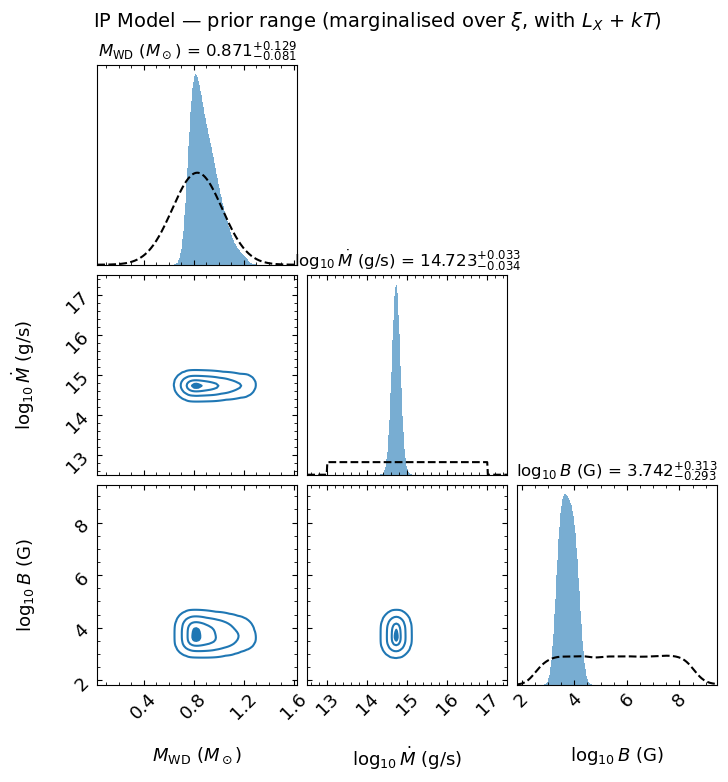

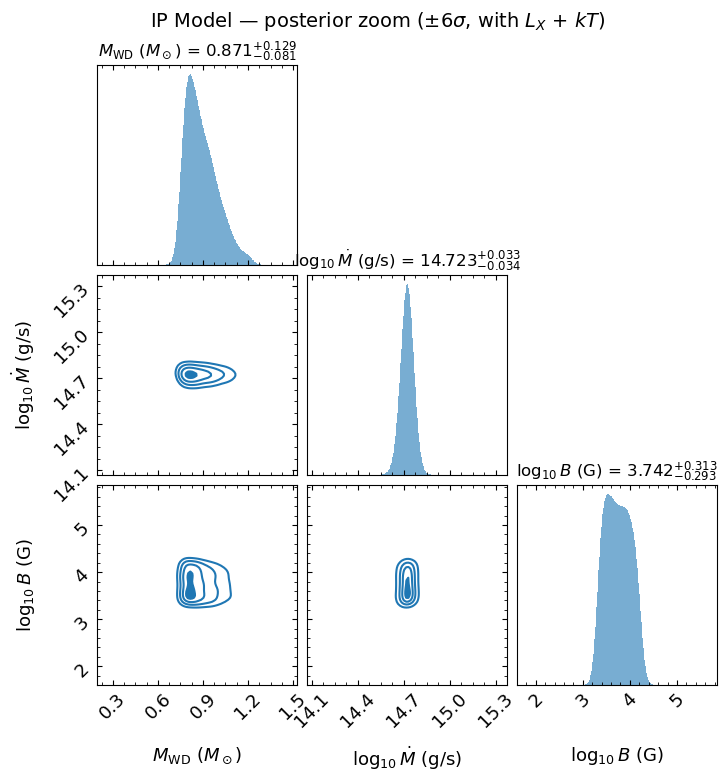

In [83]:
# --- IP corner plot (M_WD, log Mdot, log B) with prior overlays ---
# Modify column 2 in place (logmu -> logB) and use dims=[0, 1, 2] to drop xi
# from the display; xi is marginalised simply by not being plotted.
import copy
from scipy.stats import gaussian_kde


def _results_for_display(results):
    """Deepcopy a dynesty Results object and replace column 2 (log mu) with
    log10 B = log10 mu - 3 log10 R, in place."""
    rcp = copy.deepcopy(results)
    samp = rcp['samples']
    R_arr = get_R(samp[:, 0])
    samp[:, 2] = samp[:, 2] - 3 * np.log10(R_arr)
    return rcp


def overlay_prior(ax, grid, pdf, **kwargs):
    """Scale prior PDF to match histogram area (reads ax.patches from dyplot bars)."""
    hist_area = sum(p.get_width() * p.get_height()
                    for p in ax.patches if p.get_height() > 0)
    if hist_area <= 0:
        return
    prior_area = np.trapezoid(pdf, grid)
    if prior_area <= 0:
        return
    pdf_scaled = pdf * (hist_area / prior_area)
    ax.plot(grid, pdf_scaled, **kwargs)
    ymax = max(ax.get_ylim()[1], pdf_scaled.max() * 1.05)
    ax.set_ylim([0, ymax])


results_ip_B = _results_for_display(results_ip)

# Compute B prior samples for overlay (log-uniform mu marginalised over N(M))
np.random.seed(42)
N_prior = 50000
M_prior = np.random.normal(POP_M_MU, POP_M_SIG, N_prior)
M_prior = np.clip(M_prior, M_min_table + 0.001, M_max_table - 0.001)
logmu_prior = np.random.uniform(LOGMU_LO, LOGMU_HI, N_prior)
R_prior = get_R(M_prior)
logB_prior = logmu_prior - 3 * np.log10(R_prior)

labels_ip = [r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)',
             r'$\log_{10} B$ (G)']

# --- Prior-range view ---
span_ip_wide = [
    (POP_M_MU - 4*POP_M_SIG, POP_M_MU + 4*POP_M_SIG),
    (LOGMDOT_LO - 0.5, LOGMDOT_HI + 0.5),
    (np.min(logB_prior), np.max(logB_prior) - 3),
]

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B, dims=[0, 1, 2], span=span_ip_wide, labels=labels_ip,
    quantiles_2d=[0.1, 0.55, 0.93, 0.999],
    quantiles=None, show_titles=True,
    title_quantiles=[0.16, 0.5, 0.84], title_fmt='.3f',
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C0',
)

# Overlay priors on diagonals
ax = axes[0, 0]
M_grid = np.linspace(*span_ip_wide[0], 300)
overlay_prior(ax, M_grid, norm.pdf(M_grid, POP_M_MU, POP_M_SIG),
              color='k', ls='--', lw=1.5, label='Prior')
ax = axes[1, 1]
Mdot_grid = np.linspace(*span_ip_wide[1], 300)
Mdot_prior_pdf = np.where((Mdot_grid >= LOGMDOT_LO) & (Mdot_grid <= LOGMDOT_HI),
                           1.0 / (LOGMDOT_HI - LOGMDOT_LO), 0.0)
overlay_prior(ax, Mdot_grid, Mdot_prior_pdf, color='k', ls='--', lw=1.5)
ax = axes[2, 2]
kde_B = gaussian_kde(logB_prior)
B_grid = np.linspace(*span_ip_wide[2], 300)
overlay_prior(ax, B_grid, kde_B(B_grid), color='k', ls='--', lw=1.5)

fig.suptitle(r'IP Model — prior range (marginalised over $\xi$, with $L_X$ + $kT$)',
             fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip_spectral.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


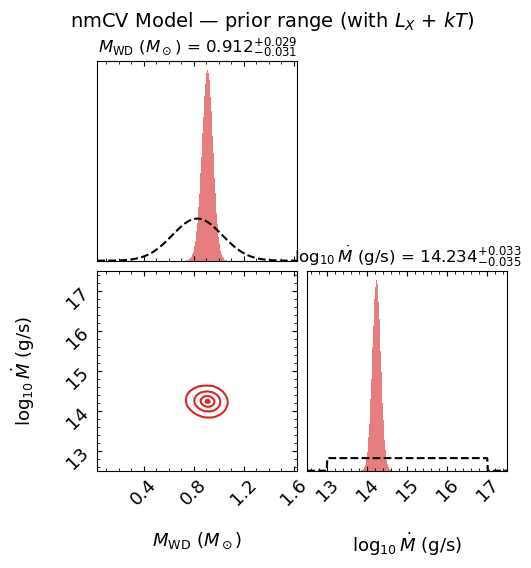

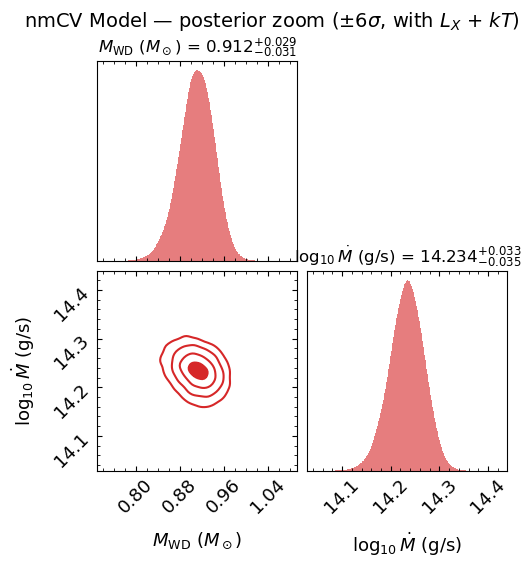

In [55]:
# --- nmCV corner plot (M_WD, log Mdot) with prior overlays ---
span_nmcv_wide = [
    (POP_M_MU - 4*POP_M_SIG, POP_M_MU + 4*POP_M_SIG),
    (LOGMDOT_LO - 0.5, LOGMDOT_HI + 0.5),
]

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_nmcv, span=span_nmcv_wide,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)'],
    quantiles=None, show_titles=True,
    quantiles_2d=[0.1, 0.55, 0.93, 0.999],
    title_quantiles=[0.16, 0.5, 0.84], title_fmt='.3f',
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C3',
)

ax = axes[0, 0]
M_grid = np.linspace(*span_nmcv_wide[0], 300)
overlay_prior(ax, M_grid, norm.pdf(M_grid, POP_M_MU, POP_M_SIG),
              color='k', ls='--', lw=1.5, label='Prior')
ax = axes[1, 1]
Mdot_grid = np.linspace(*span_nmcv_wide[1], 300)
Mdot_prior_pdf = np.where((Mdot_grid >= LOGMDOT_LO) & (Mdot_grid <= LOGMDOT_HI),
                           1.0 / (LOGMDOT_HI - LOGMDOT_LO), 0.0)
overlay_prior(ax, Mdot_grid, Mdot_prior_pdf, color='k', ls='--', lw=1.5)

fig.suptitle('nmCV Model — prior range (with $L_X$ + $kT$)', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_nmcv_spectral.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True

### Predicted $\dot{P}$ Distribution

nmCV:  Pdot = -3.92e-17  (+3.14e-18 / -3.23e-18)
       range = [-5.30e-17, -2.67e-17]
       100.0% within 1-sigma of Pdot=0;  100.0% within 2-sigma

IP:  Pdot = -1.60e-16  (+1.40e-16 / -3.11e-16)
       range = [-4.48e-15, 1.44e-15]
       98.8% within 1-sigma of Pdot=0;  100.0% within 2-sigma



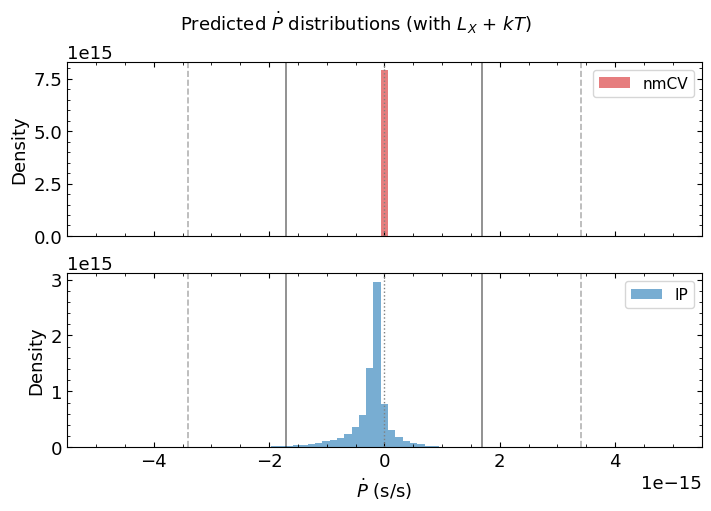

In [56]:
# Compute Pdot from posterior samples
Pdot_nmcv_samples = np.array([
    pdot_nmcv(s[0], s[1]) for s in samples_nmcv_eq
])
Pdot_ip_samples = np.array([
    pdot_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_eq
])

# --- Print summary statistics ---
for name, samp in [('nmCV', Pdot_nmcv_samples), ('IP', Pdot_ip_samples)]:
    med = np.median(samp)
    lo, hi = np.percentile(samp, [16, 84])
    mn, mx = samp.min(), samp.max()
    print(f"{name}:  Pdot = {med:.2e}  (+{hi-med:.2e} / {lo-med:.2e})")
    print(f"       range = [{mn:.2e}, {mx:.2e}]")
    frac_consistent = np.mean(np.abs(samp) < sigma_Pdot) * 100
    frac_2sig = np.mean(np.abs(samp) < 2*sigma_Pdot) * 100
    print(f"       {frac_consistent:.1f}% within 1-sigma of Pdot=0;  {frac_2sig:.1f}% within 2-sigma")
    print()

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(7, 5), sharex=True,
                                      gridspec_kw={'height_ratios': [1, 1]})

bins = np.linspace(-5e-15, 5e-15, 80)
ax_top.hist(Pdot_nmcv_samples, bins=bins, density=True, alpha=0.6, color='C3', label='nmCV')
ax_bot.hist(Pdot_ip_samples, bins=bins, density=True, alpha=0.6, color='C0', label='IP')

for ax in [ax_top, ax_bot]:
    ax.axvline(0, color='gray', ls=':', lw=1)
    for nsig, ls, alph in [(1, '-', 0.5), (2, '--', 0.3)]:
        ax.axvline(nsig * sigma_Pdot, color='k', ls=ls, alpha=alph, lw=1.2)
        ax.axvline(-nsig * sigma_Pdot, color='k', ls=ls, alpha=alph, lw=1.2)
    ax.legend(fontsize=11)
    ax.set_ylabel('Density')

ax_bot.set_xlabel(r'$\dot{P}$ (s/s)')
fig.suptitle(r'Predicted $\dot{P}$ distributions (with $L_X$ + $kT$)', fontsize=13)
fig.savefig(f'{savedir}/bayesian_pdot_posterior_spectral.pdf', bbox_inches='tight')
plt.show()


### Posterior Predictive Check

Compare the predicted observables ($kT$, $L_X$) from the posterior to the observed values.
This verifies the models actually reproduce the spectral data, and shows the per-observable
$\chi^2$ contribution.

=== Per-observable chi^2 across posterior samples ===

nmCV:  (50th, 84th, 95th, 99th percentile)
  chi2(Pdot) =   0.00    0.00    0.00    0.00
  chi2(kT)   =   0.45    1.94    3.81    6.66
  chi2(L_X)  =   0.46    2.02    3.81    6.71
  total median = 1.39

IP:  (50th, 84th, 95th, 99th percentile)
  chi2(Pdot) =   0.01    0.09    0.36    1.15
  chi2(kT)   =   0.46    1.91    3.64    6.59
  chi2(L_X)  =   0.45    1.91    3.82    6.63
  total median = 1.44



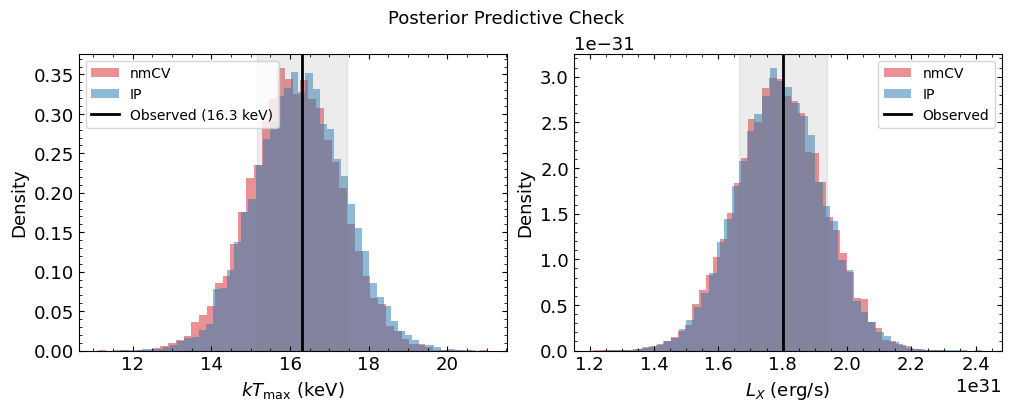

In [57]:
# --- Predicted kT and L_X from posterior ---
kT_nmcv_pred = np.array([kT_nmcv(s[0]) for s in samples_nmcv_eq])
LX_nmcv_pred = np.array([LX_nmcv(s[0], s[1]) for s in samples_nmcv_eq])

kT_ip_pred = np.array([kT_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_eq])
LX_ip_pred = np.array([LX_ip(s[0], s[1], s[2], s[3]) for s in samples_ip_eq])

# --- Chi-squared breakdown (percentiles: 50th, 84th, 95th, 99th) ---
print("=== Per-observable chi^2 across posterior samples ===\n")
for name, Pdot_s, kT_s, LX_s in [
    ('nmCV', Pdot_nmcv_samples, kT_nmcv_pred, LX_nmcv_pred),
    ('IP',   Pdot_ip_samples,   kT_ip_pred,   LX_ip_pred),
]:
    chi2_Pdot = ((Pdot_obs - Pdot_s) / sigma_Pdot)**2
    chi2_kT   = ((kT_obs   - kT_s)   / sigma_kT)**2
    chi2_LX   = ((L_X_obs  - LX_s)   / sigma_LX)**2
    print(f"{name}:  (50th, 84th, 95th, 99th percentile)")
    for label, x in [('chi2(Pdot)', chi2_Pdot), ('chi2(kT)  ', chi2_kT),
                     ('chi2(L_X) ', chi2_LX)]:
        p = np.percentile(x, [50, 84, 95, 99])
        print(f"  {label} = {p[0]:6.2f}  {p[1]:6.2f}  {p[2]:6.2f}  {p[3]:6.2f}")
    print(f"  total median = {np.median(chi2_Pdot+chi2_kT+chi2_LX):.2f}\n")

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# kT panel
ax = axes[0]
ax.hist(kT_nmcv_pred, bins=50, density=True, alpha=0.5, color='C3', label='nmCV')
ax.hist(kT_ip_pred,   bins=50, density=True, alpha=0.5, color='C0', label='IP')
ax.axvline(kT_obs, color='k', lw=2, label=f'Observed ({kT_obs} keV)')
ax.axvspan(kT_obs - sigma_kT, kT_obs + sigma_kT, alpha=0.15, color='gray')
ax.set_xlabel(r'$kT_{\rm max}$ (keV)')
ax.set_ylabel('Density')
ax.legend(fontsize=10)

# L_X panel
ax = axes[1]
ax.hist(LX_nmcv_pred, bins=50, density=True, alpha=0.5, color='C3', label='nmCV')
ax.hist(LX_ip_pred,   bins=50, density=True, alpha=0.5, color='C0', label='IP')
ax.axvline(L_X_obs, color='k', lw=2, label='Observed')
ax.axvspan(L_X_obs - sigma_LX, L_X_obs + sigma_LX, alpha=0.15, color='gray')
ax.set_xlabel(r'$L_X$ (erg/s)')
ax.set_ylabel('Density')
ax.legend(fontsize=10)

fig.suptitle('Posterior Predictive Check', fontsize=13)
fig.savefig(f'{savedir}/bayesian_predictive_check_spectral.pdf', bbox_inches='tight')
plt.show()


r_m / r_co:  median = 0.702  (0.498 -- 0.894, 68%)


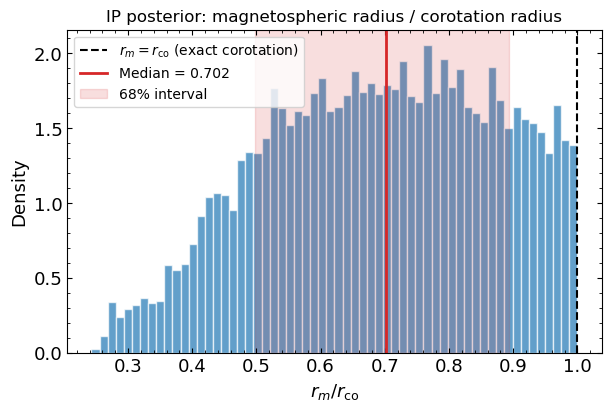

In [58]:
# --- r_m / r_co posterior (spin-equilibrium diagnostic) ---
rm_over_rco = np.zeros(len(samples_ip_eq))
for i, s in enumerate(samples_ip_eq):
    M_wd_s, log_Mdot_s, log_mu_s, xi_s = s
    M_s = M_wd_s * Msun
    Mdot_s = 10**log_Mdot_s
    mu_s = 10**log_mu_s
    r_m_s = xi_s * (mu_s**4 / (2 * G * M_s * Mdot_s**2))**(1.0/7.0)
    r_co_s = (G * M_s * P**2 / (4 * np.pi**2))**(1.0/3.0)
    rm_over_rco[i] = r_m_s / r_co_s

med_rr = np.median(rm_over_rco)
lo_rr, hi_rr = np.percentile(rm_over_rco, [16, 84])
print(f"r_m / r_co:  median = {med_rr:.3f}  ({lo_rr:.3f} -- {hi_rr:.3f}, 68%)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(rm_over_rco, bins=60, density=True, color='C0', alpha=0.7, edgecolor='white')
ax.axvline(1.0, color='k', ls='--', lw=1.5, label=r'$r_m = r_{\rm co}$ (exact corotation)')
ax.axvline(med_rr, color='C3', lw=2, label=f'Median = {med_rr:.3f}')
ax.axvspan(lo_rr, hi_rr, alpha=0.15, color='C3', label='68% interval')
ax.set_xlabel(r'$r_m / r_{\rm co}$', fontsize=13)
ax.set_ylabel('Density', fontsize=13)
ax.set_title(r'IP posterior: magnetospheric radius / corotation radius', fontsize=12)
ax.legend(fontsize=10)
fig.savefig(f'{savedir}/bayesian_rm_rco_posterior.pdf', bbox_inches='tight')
plt.show()


Spin-evolution timescale (IP):
  tau = P/|Pdot|:  median = 5.06e+09 yr  (1.82e+09 -- 1.03e+10, 68%)
  log10(tau/yr):   median = 9.7
  >> Gyr: consistent with long-term spin equilibrium


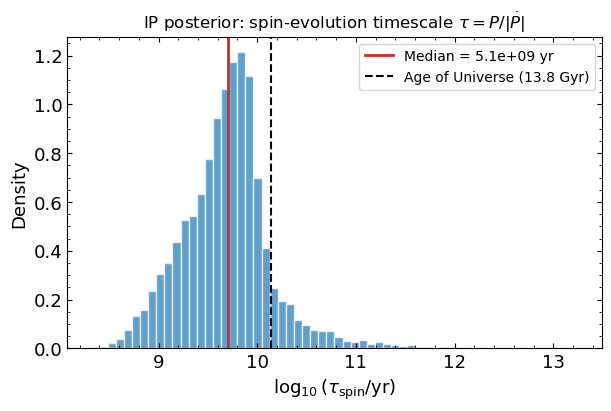

In [59]:
# --- Spin-evolution timescale tau = P / |Pdot| ---
tau_s = P / np.abs(Pdot_ip_samples)  # seconds
tau_yr = tau_s / (365.25 * 86400)

med_tau = np.median(tau_yr)
lo_tau, hi_tau = np.percentile(tau_yr, [16, 84])
print(f"Spin-evolution timescale (IP):")
print(f"  tau = P/|Pdot|:  median = {med_tau:.2e} yr  ({lo_tau:.2e} -- {hi_tau:.2e}, 68%)")
print(f"  log10(tau/yr):   median = {np.log10(med_tau):.1f}")
if med_tau > 1e9:
    print(f"  >> Gyr: consistent with long-term spin equilibrium")

fig, ax = plt.subplots(figsize=(6, 4))
log_tau = np.log10(tau_yr)
log_tau_finite = log_tau[np.isfinite(log_tau)]
ax.hist(log_tau_finite, bins=60, density=True, color='C0', alpha=0.7, edgecolor='white')
ax.axvline(np.log10(med_tau), color='C3', lw=2, label=f'Median = {med_tau:.1e} yr')
ax.axvline(np.log10(13.8e9), color='k', ls='--', lw=1.5, label='Age of Universe (13.8 Gyr)')
ax.set_xlabel(r'$\log_{10}(\tau_{\rm spin} / {\rm yr})$', fontsize=13)
ax.set_ylabel('Density', fontsize=13)
ax.set_title(r'IP posterior: spin-evolution timescale $\tau = P / |\dot P|$', fontsize=12)
ax.legend(fontsize=10)
fig.savefig(f'{savedir}/bayesian_spin_timescale.pdf', bbox_inches='tight')
plt.show()


## Impact of $\dot{P}$ Measurement

Compare results with the **new** timing constraint ($\sigma_{\dot{P}} = 1.7 \times 10^{-15}$ s/s)
versus the **old** constraint ($\sigma_{\dot{P}} = 1.8 \times 10^{-12}$ s/s, essentially no Pdot information).
This isolates how much the improved timing measurement adds beyond the spectral constraints alone.

In [60]:
# --- Re-run with old (weak) Pdot constraint ---
# Same sampler + priors + accreting-IP likelihood as the main runs so that
# the ln Z comparison between "new" and "old" Pdot constraints is
# apples-to-apples for the Bayes factor.
sigma_Pdot_old = 1.8e-12  # old 1-sigma: essentially no constraint

def log_likelihood_nmcv_old(theta):
    M_wd, log_Mdot = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100
    Pdot_pred = pdot_nmcv(M_wd, log_Mdot)
    kT_pred = kT_nmcv(M_wd)
    LX_pred = LX_nmcv(M_wd, log_Mdot)
    chi2  = ((Pdot_obs - Pdot_pred) / sigma_Pdot_old)**2
    chi2 += ((kT_obs - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    return -0.5 * chi2


def log_likelihood_ip_old(theta):
    M_wd, log_Mdot, log_mu, xi_s = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100

    Pdot_pred = pdot_ip(M_wd, log_Mdot, log_mu, xi_s)
    kT_pred   = kT_ip (M_wd, log_Mdot, log_mu, xi_s)
    LX_pred   = LX_ip (M_wd, log_Mdot, log_mu, xi_s)
    if (np.isnan(Pdot_pred) or np.isnan(kT_pred) or np.isnan(LX_pred)
            or kT_pred <= 0 or LX_pred <= 0):
        return -1e100

    chi2  = ((Pdot_obs - Pdot_pred) / sigma_Pdot_old)**2
    chi2 += ((kT_obs  - kT_pred)    / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred)    / sigma_LX)**2
    return -0.5 * chi2


print("Running IP sampling with OLD Pdot constraint (4D)...")
sampler_ip_old = dynesty.DynamicNestedSampler(
    log_likelihood_ip_old, prior_transform_ip, ndim=4,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(44))
)
sampler_ip_old.run_nested(print_progress=True)
results_ip_old = sampler_ip_old.results
print(f"IP (old): logZ = {results_ip_old['logz'][-1]:.2f} +/- {results_ip_old['logzerr'][-1]:.2f}")

print("\nRunning nmCV sampling with OLD Pdot constraint...")
sampler_nmcv_old = dynesty.DynamicNestedSampler(
    log_likelihood_nmcv_old, prior_transform_nmcv, ndim=2,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(45))
)
sampler_nmcv_old.run_nested(print_progress=True)
results_nmcv_old = sampler_nmcv_old.results
print(f"nmCV (old): logZ = {results_nmcv_old['logz'][-1]:.2f} +/- {results_nmcv_old['logzerr'][-1]:.2f}")


Running IP sampling with OLD Pdot constraint (4D)...


30903it [01:31, 336.65it/s, batch: 1 | bound: 4 | nc: 1 | ncall: 647452 | eff(%):  4.456 | loglstar: -1.878 < -0.000 < -0.506 | logz: -8.874 +/-  0.065 | stop:  0.735]                       


IP (old): logZ = -8.87 +/- 0.05

Running nmCV sampling with OLD Pdot constraint...


27569it [01:10, 391.57it/s, batch: 1 | bound: 2 | nc: 1 | ncall: 434684 | eff(%):  5.783 | loglstar: -1.907 < -0.000 < -0.533 | logz: -5.880 +/-  0.051 | stop:  0.736]                    

nmCV (old): logZ = -5.88 +/- 0.04


In [61]:
# --- Extract old-constraint posteriors ---
w_ip_old = np.exp(results_ip_old['logwt'] - results_ip_old['logz'][-1])
w_ip_old /= w_ip_old.sum()
samples_ip_old_eq = dyfunc.resample_equal(results_ip_old['samples'], w_ip_old)

w_nmcv_old = np.exp(results_nmcv_old['logwt'] - results_nmcv_old['logz'][-1])
w_nmcv_old /= w_nmcv_old.sum()
samples_nmcv_old_eq = dyfunc.resample_equal(results_nmcv_old['samples'], w_nmcv_old)

# Derived B for IP old
R_old = get_R(samples_ip_old_eq[:, 0])
log10_B_old = samples_ip_old_eq[:, 2] - 3 * np.log10(R_old)

# --- Comparison table ---
def fmt(samples, idx):
    med = np.median(samples[:, idx])
    lo, hi = np.percentile(samples[:, idx], [16, 84])
    return f"{med:.3f} (+{hi-med:.3f}/-{med-lo:.3f})"

print("=== Posterior comparison: new vs old Pdot constraint ===\n")
header = f"{'Parameter':<22s} {'nmCV (new)':<28s} {'nmCV (old)':<28s}"
print(header)
print("-" * len(header))
print(f"{'M_WD [Msun]':<22s} {fmt(samples_nmcv_eq, 0):<28s} {fmt(samples_nmcv_old_eq, 0):<28s}")
print(f"{'log10(Mdot) [g/s]':<22s} {fmt(samples_nmcv_eq, 1):<28s} {fmt(samples_nmcv_old_eq, 1):<28s}")
print()

header = f"{'Parameter':<22s} {'IP (new)':<28s} {'IP (old)':<28s}"
print(header)
print("-" * len(header))
print(f"{'M_WD [Msun]':<22s} {fmt(samples_ip_eq, 0):<28s} {fmt(samples_ip_old_eq, 0):<28s}")
print(f"{'log10(Mdot) [g/s]':<22s} {fmt(samples_ip_eq, 1):<28s} {fmt(samples_ip_old_eq, 1):<28s}")
print(f"{'log10(mu) [G cm^3]':<22s} {fmt(samples_ip_eq, 2):<28s} {fmt(samples_ip_old_eq, 2):<28s}")
print(f"{'xi':<22s} {fmt(samples_ip_eq, 3):<28s} {fmt(samples_ip_old_eq, 3):<28s}")

med_B_new = np.median(log10_B_samples_ip)
med_B_old = np.median(log10_B_old)
lo_B_new, hi_B_new = np.percentile(log10_B_samples_ip, [16, 84])
lo_B_old, hi_B_old = np.percentile(log10_B_old, [16, 84])
new_B = f"{med_B_new:.2f} (+{hi_B_new-med_B_new:.2f}/-{med_B_new-lo_B_new:.2f})"
old_B = f"{med_B_old:.2f} (+{hi_B_old-med_B_old:.2f}/-{med_B_old-lo_B_old:.2f})"
print(f"{'log10(B) [G]':<22s} {new_B:<28s} {old_B:<28s}")

print("\n=== Bayes factor comparison ===")
logZ_ip_new = results_ip['logz'][-1]
logZ_nmcv_new = results_nmcv['logz'][-1]
logZ_ip_o = results_ip_old['logz'][-1]
logZ_nmcv_o = results_nmcv_old['logz'][-1]
lnBF_new = logZ_ip_new - logZ_nmcv_new
lnBF_old = logZ_ip_o - logZ_nmcv_o
print(f"  ln(BF_IP/nmCV) new Pdot: {lnBF_new:+.2f}  (BF = {np.exp(lnBF_new):.4f})")
print(f"  ln(BF_IP/nmCV) old Pdot: {lnBF_old:+.2f}  (BF = {np.exp(lnBF_old):.4f})")


=== Posterior comparison: new vs old Pdot constraint ===

Parameter              nmCV (new)                   nmCV (old)                  
--------------------------------------------------------------------------------
M_WD [Msun]            0.912 (+0.030/-0.031)        0.912 (+0.030/-0.032)       
log10(Mdot) [g/s]      14.234 (+0.033/-0.035)       14.234 (+0.034/-0.036)      

Parameter              IP (new)                     IP (old)                    
--------------------------------------------------------------------------------
M_WD [Msun]            0.871 (+0.129/-0.081)        0.864 (+0.132/-0.076)       
log10(Mdot) [g/s]      14.723 (+0.033/-0.034)       14.724 (+0.033/-0.036)      
log10(mu) [G cm^3]     30.071 (+0.357/-0.328)       30.111 (+0.348/-0.339)      
xi                     0.573 (+0.271/-0.196)        0.548 (+0.278/-0.186)       
log10(B) [G]           3.74 (+0.31/-0.29)           3.78 (+0.31/-0.31)          

=== Bayes factor comparison ===
  ln(BF_IP/nmCV) 

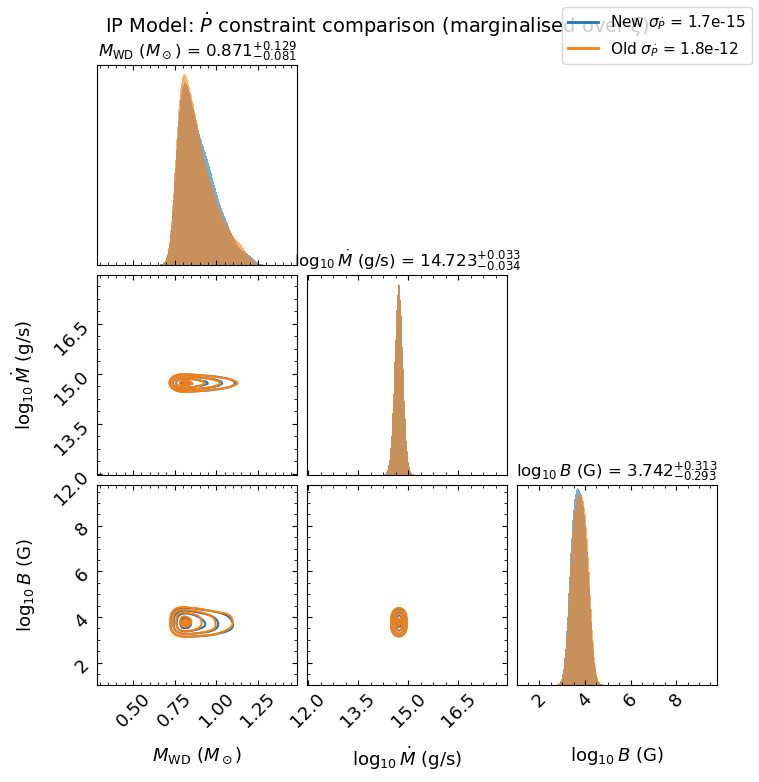

In [62]:
# --- Overlay IP corner plots: new (blue) vs old (orange) Pdot constraint ---
# Same deepcopy + in-place logmu->logB trick as cell 16, applied to both
# results objects. xi is dropped via dims=[0, 1, 2].
results_ip_B_new = _results_for_display(results_ip)
results_ip_B_old = _results_for_display(results_ip_old)

# Span encompassing both posteriors
all_ip = np.vstack([results_ip_B_new['samples'], results_ip_B_old['samples']])
span_ip_cmp = []
for j in range(3):
    lo, hi = np.percentile(all_ip[:, j], [0.5, 99.5])
    w = hi - lo
    span_ip_cmp.append((lo - 0.3 * w, hi + 0.3 * w))

labels_ip_cmp = [r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)',
                 r'$\log_{10} B$ (G)']

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B_new, dims=[0, 1, 2], span=span_ip_cmp, labels=labels_ip_cmp,
    quantiles=None, show_titles=True, title_quantiles=[0.16, 0.5, 0.84],
    title_fmt='.3f', title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C0',
)
dyplot.cornerplot(
    results_ip_B_old, dims=[0, 1, 2], span=span_ip_cmp, labels=labels_ip_cmp,
    quantiles=None, show_titles=False,
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C1', fig=(fig, axes),
)

from matplotlib.lines import Line2D
fig.legend(handles=[
    Line2D([0], [0], color='C0', lw=2, label=r'New $\sigma_{\dot{P}}$ = 1.7e-15'),
    Line2D([0], [0], color='C1', lw=2, label=r'Old $\sigma_{\dot{P}}$ = 1.8e-12'),
], loc='upper right', fontsize=11, frameon=True)
fig.suptitle(r'IP Model: $\dot P$ constraint comparison (marginalised over $\xi$)',
             fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip_pdot_comparison.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


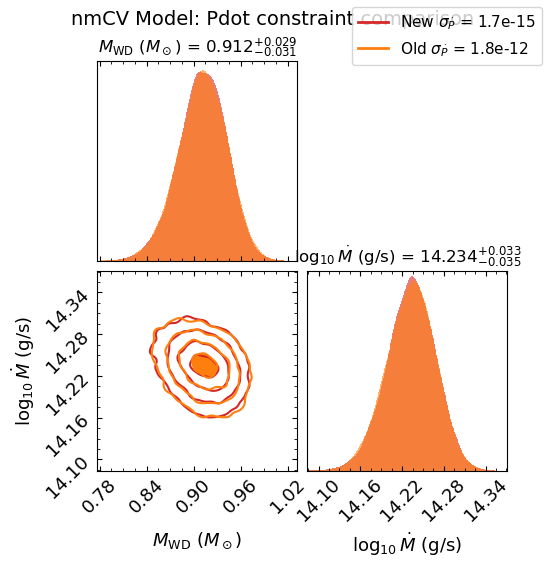

In [63]:
# --- Overlay nmCV corner plots: new (red) vs old (orange) Pdot constraint ---
all_nmcv = np.vstack([samples_nmcv_eq, samples_nmcv_old_eq])
span_nmcv_cmp = []
for col in [all_nmcv[:, 0], all_nmcv[:, 1]]:
    lo, hi = np.percentile(col, [0.5, 99.5])
    w = hi - lo
    span_nmcv_cmp.append((lo - 0.3*w, hi + 0.3*w))

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_nmcv, span=span_nmcv_cmp,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)'],
    quantiles=None, show_titles=True, title_quantiles=[0.16, 0.5, 0.84],
    title_fmt='.3f', title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C3',
)
dyplot.cornerplot(
    results_nmcv_old, span=span_nmcv_cmp,
    labels=[r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)'],
    quantiles=None, show_titles=False,
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C1', fig=(fig, axes),
)
fig.legend(handles=[
    Line2D([0], [0], color='C3', lw=2, label=r'New $\sigma_{\dot{P}}$ = 1.7e-15'),
    Line2D([0], [0], color='C1', lw=2, label=r'Old $\sigma_{\dot{P}}$ = 1.8e-12'),
], loc='upper right', fontsize=11, frameon=True)
fig.suptitle('nmCV Model: Pdot constraint comparison', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_nmcv_pdot_comparison.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True

## $\dot{P}$ Leverage Check (spectral-only re-run)

The posterior comparison above (new vs old $\sigma_{\dot P}$) showed essentially identical posteriors.  To verify that this is because $\dot{P}$ adds little information on top of the spectral data — not because of a model bug — we re-run the inference with $\dot{P}$ **removed entirely** from the likelihood (kT + $L_X$ only).  If the spectral-only posterior matches the with-$\dot{P}$ posterior, then $\dot{P}$ is a consistency check rather than a constraint.


In [64]:
# --- Spectral-only likelihood (drop Pdot) ---
def log_likelihood_nmcv_specOnly(theta):
    M_wd, log_Mdot = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100
    kT_pred = kT_nmcv(M_wd)
    LX_pred = LX_nmcv(M_wd, log_Mdot)
    chi2  = ((kT_obs  - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    return -0.5 * chi2


def log_likelihood_ip_specOnly(theta):
    M_wd, log_Mdot, log_mu, xi_s = theta
    if M_wd <= M_min_table or M_wd >= M_max_table:
        return -1e100
    kT_pred = kT_ip(M_wd, log_Mdot, log_mu, xi_s)
    LX_pred = LX_ip(M_wd, log_Mdot, log_mu, xi_s)
    if (np.isnan(kT_pred) or np.isnan(LX_pred)
            or kT_pred <= 0 or LX_pred <= 0):
        return -1e100
    chi2  = ((kT_obs  - kT_pred) / sigma_kT)**2
    chi2 += ((L_X_obs - LX_pred) / sigma_LX)**2
    return -0.5 * chi2


print("Running IP nested sampling (spectral-only, no Pdot)...")
sampler_ip_so = dynesty.DynamicNestedSampler(
    log_likelihood_ip_specOnly, prior_transform_ip, ndim=4,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(46))
)
sampler_ip_so.run_nested(print_progress=True)
results_ip_so = sampler_ip_so.results
print(f"IP (spec-only): logZ = {results_ip_so['logz'][-1]:.2f} +/- {results_ip_so['logzerr'][-1]:.2f}")

print("\nRunning nmCV nested sampling (spectral-only, no Pdot)...")
sampler_nmcv_so = dynesty.DynamicNestedSampler(
    log_likelihood_nmcv_specOnly, prior_transform_nmcv, ndim=2,
    nlive=2000, bound='multi', sample='rwalk',
    rstate=np.random.Generator(np.random.PCG64(47))
)
sampler_nmcv_so.run_nested(print_progress=True)
results_nmcv_so = sampler_nmcv_so.results
print(f"nmCV (spec-only): logZ = {results_nmcv_so['logz'][-1]:.2f} +/- {results_nmcv_so['logzerr'][-1]:.2f}")

# Equal-weight samples
w_ip_so = np.exp(results_ip_so['logwt'] - results_ip_so['logz'][-1])
w_ip_so /= w_ip_so.sum()
samples_ip_so_eq = dyfunc.resample_equal(results_ip_so['samples'], w_ip_so)

w_nmcv_so = np.exp(results_nmcv_so['logwt'] - results_nmcv_so['logz'][-1])
w_nmcv_so /= w_nmcv_so.sum()
samples_nmcv_so_eq = dyfunc.resample_equal(results_nmcv_so['samples'], w_nmcv_so)

# log B for IP spec-only
R_so = get_R(samples_ip_so_eq[:, 0])
log10_B_so = samples_ip_so_eq[:, 2] - 3 * np.log10(R_so)

# Side-by-side parameter comparison: with-Pdot vs spectral-only
def fmt(samples, idx):
    med = np.median(samples[:, idx])
    lo, hi = np.percentile(samples[:, idx], [16, 84])
    return f"{med:.3f} (+{hi-med:.3f}/-{med-lo:.3f})"

print("\n=== Parameter posteriors: with Pdot vs spectral-only ===")
hdr = f"{'Parameter':<22s} {'with Pdot':<28s} {'spectral-only':<28s}"
print(hdr); print("-" * len(hdr))
print(f"{'IP M_WD [Msun]':<22s} {fmt(samples_ip_eq, 0):<28s} {fmt(samples_ip_so_eq, 0):<28s}")
print(f"{'IP log10(Mdot)':<22s} {fmt(samples_ip_eq, 1):<28s} {fmt(samples_ip_so_eq, 1):<28s}")
print(f"{'IP log10(mu)':<22s} {fmt(samples_ip_eq, 2):<28s} {fmt(samples_ip_so_eq, 2):<28s}")
print(f"{'IP xi':<22s} {fmt(samples_ip_eq, 3):<28s} {fmt(samples_ip_so_eq, 3):<28s}")
mB1 = np.median(log10_B_samples_ip); l1, h1 = np.percentile(log10_B_samples_ip, [16, 84])
mB2 = np.median(log10_B_so);         l2, h2 = np.percentile(log10_B_so, [16, 84])
print(f"{'IP log10(B)':<22s} {mB1:.2f} (+{h1-mB1:.2f}/-{mB1-l1:.2f})            "
      f"{mB2:.2f} (+{h2-mB2:.2f}/-{mB2-l2:.2f})")
print(f"{'nmCV M_WD [Msun]':<22s} {fmt(samples_nmcv_eq, 0):<28s} {fmt(samples_nmcv_so_eq, 0):<28s}")
print(f"{'nmCV log10(Mdot)':<22s} {fmt(samples_nmcv_eq, 1):<28s} {fmt(samples_nmcv_so_eq, 1):<28s}")

# Bayes factor IP vs nmCV in each setting
lnZ_ip_full   = results_ip['logz'][-1]
lnZ_nmcv_full = results_nmcv['logz'][-1]
lnZ_ip_so    = results_ip_so['logz'][-1]
lnZ_nmcv_so  = results_nmcv_so['logz'][-1]
print("\n=== Bayes factor IP vs nmCV ===")
print(f"  with Pdot:     ln BF = {lnZ_ip_full - lnZ_nmcv_full:+.2f}")
print(f"  spectral-only: ln BF = {lnZ_ip_so   - lnZ_nmcv_so:+.2f}")


Running IP nested sampling (spectral-only, no Pdot)...


30381it [01:14, 406.93it/s, batch: 1 | bound: 3 | nc: 1 | ncall: 634992 | eff(%):  4.461 | loglstar: -1.879 < -0.000 < -0.487 | logz: -8.649 +/-  0.064 | stop:  0.742]                       


IP (spec-only): logZ = -8.65 +/- 0.05

Running nmCV nested sampling (spectral-only, no Pdot)...


27519it [00:56, 487.12it/s, batch: 1 | bound: 2 | nc: 1 | ncall: 434974 | eff(%):  5.769 | loglstar: -1.831 < -0.000 < -0.455 | logz: -5.739 +/-  0.051 | stop:  0.740]                    


nmCV (spec-only): logZ = -5.75 +/- 0.04

=== Parameter posteriors: with Pdot vs spectral-only ===
Parameter              with Pdot                    spectral-only               
--------------------------------------------------------------------------------
IP M_WD [Msun]         0.871 (+0.129/-0.081)        0.872 (+0.132/-0.083)       
IP log10(Mdot)         14.723 (+0.033/-0.034)       14.724 (+0.034/-0.035)      
IP log10(mu)           30.071 (+0.357/-0.328)       30.106 (+0.340/-0.330)      
IP xi                  0.573 (+0.271/-0.196)        0.538 (+0.279/-0.176)       
IP log10(B)            3.74 (+0.31/-0.29)            3.79 (+0.30/-0.32)
nmCV M_WD [Msun]       0.912 (+0.030/-0.031)        0.913 (+0.030/-0.032)       
nmCV log10(Mdot)       14.234 (+0.033/-0.035)       14.234 (+0.034/-0.036)      

=== Bayes factor IP vs nmCV ===
  with Pdot:     ln BF = -3.15
  spectral-only: ln BF = -2.90


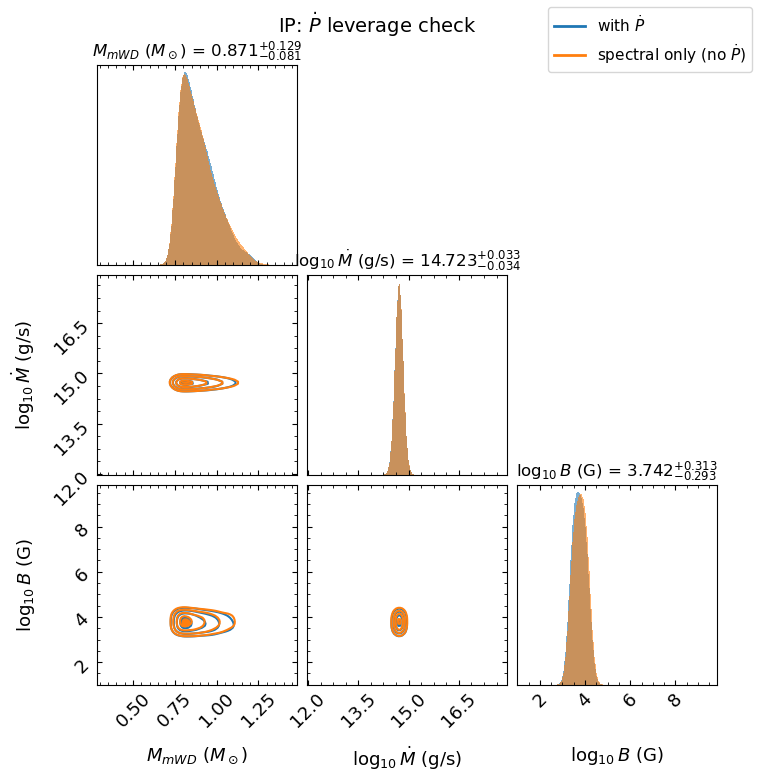

In [65]:
# --- Overlay IP corner: with Pdot (blue) vs spectral-only (orange) ---
results_ip_B_full = _results_for_display(results_ip)
results_ip_B_so   = _results_for_display(results_ip_so)

all_ip_so = np.vstack([results_ip_B_full['samples'], results_ip_B_so['samples']])
span_so = []
for j in range(3):
    lo, hi = np.percentile(all_ip_so[:, j], [0.5, 99.5])
    w = hi - lo
    span_so.append((lo - 0.3 * w, hi + 0.3 * w))

labels_so = [r'$M_{\rm WD}$ ($M_\odot$)', r'$\log_{10}\dot{M}$ (g/s)',
             r'$\log_{10} B$ (G)']

plt.rcParams['figure.constrained_layout.use'] = False
fig, axes = dyplot.cornerplot(
    results_ip_B_full, dims=[0, 1, 2], span=span_so, labels=labels_so,
    quantiles=None, show_titles=True, title_quantiles=[0.16, 0.5, 0.84],
    title_fmt='.3f', title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C0',
)
dyplot.cornerplot(
    results_ip_B_so, dims=[0, 1, 2], span=span_so, labels=labels_so,
    quantiles=None, show_titles=False,
    title_kwargs={'fontsize': 12}, label_kwargs={'fontsize': 13},
    color='C1', fig=(fig, axes),
)
fig.legend(handles=[
    Line2D([0], [0], color='C0', lw=2, label=r'with $\dot P$'),
    Line2D([0], [0], color='C1', lw=2, label=r'spectral only (no $\dot P$)'),
], loc='upper right', fontsize=11, frameon=True)
fig.suptitle(r'IP: $\dot P$ leverage check', fontsize=14, y=1.02)
fig.savefig(f'{savedir}/bayesian_corner_ip_pdot_leverage.pdf', bbox_inches='tight')
plt.show()
plt.rcParams['figure.constrained_layout.use'] = True


## Summary

This analysis fits CJ2056 as an accreting IP (with a non-magnetic CV as a control) using:
1. Broad population priors on $M_{\rm WD}$ and $\dot M$, independent of spectral fits
2. $L_X$ and $kT_{\rm max}$ as observational constraints in the likelihood
3. $\xi$ sampled as a nuisance parameter so that the factor-$\xi^{-7/4}$ systematic on $B$ is absorbed into the posterior
4. Forward-model-level rejection of $r_m$ outside $[R_{\rm WD}, r_{\rm co}]$ — the observed hard thermal X-ray emission is an accretion-shock signature, so the propeller regime is excluded a priori

The physical equations $L_X = GM\dot{M}/R$ and $kT \propto GM/R$ naturally encode the M–$\dot{M}$ anticorrelation; the $L_X$ constraint pins $\dot{M}$ to $\sim 10^{14}$ g/s (consistent with CJ2056 being a low-luminosity IP), which propagates through $r_m \propto (\mu^4/\dot{M}^2)^{1/7}$ to tighten the $\mu$ (and thus $B$) posterior.

### Spin-equilibrium diagnostics

- The IP posterior yields $r_m / r_{\rm co} = 0.70^{+0.19}_{-0.20}$ (68%), well below exact corotation but inside the accretion regime.
- The spin-evolution timescale $\tau = P / |\dot P|$ has median $\sim 5$ Gyr (68% interval 1.8–10 Gyr), exceeding the Hubble time — consistent with long-term spin equilibrium on timescales longer than the age of the Galaxy.

### Interpretation of the spin-equilibrium diagnostics

**Are these diagnostics validity checks, or scientific inferences?** Both — but they serve different roles and carry different levels of model dependence.

*As a validity check (model-independent level).* The tight $\dot P$ measurement $|\dot P|\lesssim 2\times10^{-15}$ s/s forces $\tau = P/|\dot P|\gg$ Gyr *regardless* of any torque model: this is a direct kinematic statement. The fact that the IP posterior can simultaneously satisfy the $kT$, $L_X$, and $\dot P$ data inside the accretion regime (and not be pushed into unphysical corners of parameter space) is a consistency test of the IP framework. If the torque model were grossly wrong, the posterior would either fail to find support or concentrate at the prior edges; neither happens here.

*As a scientific inference (model-conditional level).* Conditional on the Bhattacharyya & Chakrabarty (2017) torque prescription, the posterior location $r_m/r_{\rm co}\sim 0.7$ is the *equilibrium fastness* at which the accretion spin-up torque and the outer-disk magnetic spin-down torque cancel. This yields physical outputs — a few-kG surface field, $\dot M\sim 10^{14}$ g/s, and a multi-Gyr spin-relaxation timescale — that characterise CJ2056 as an evolved, disk-fed low-$B$ IP sitting at its torque equilibrium.

*What model misspecification does (and does not) invalidate.* The *qualitative* conclusion — the accretion and magnetic torques nearly balance, and the system is near its equilibrium fastness — is robust across the common disk-torque prescriptions (Ghosh & Lamb 1979; Wang 1995; Rappaport+2004; B&C 2017), because all of them produce a torque curve that crosses zero at some $r_m/r_{\rm co}<1$ and because the data directly require $|\dot P|/P\ll 1/\tau_{\rm gyr}$. What *is* prescription-dependent is the quantitative numerical value of $r_m/r_{\rm co}$ at equilibrium, and hence the inferred $\mu$ (and $B$) at the $\mathcal{O}(10\text{--}30\%)$ level. So the statement "CJ2056 is at torque equilibrium in a low-$B$ IP geometry" survives model misspecification; the statement "$r_m/r_{\rm co}=0.70$" does not, and the quoted $B$ should be read with a corresponding systematic.

**Why does $r_m/r_{\rm co}$ peak near 0.7 rather than pile up at 1?** Spin equilibrium is *not* the condition $r_m=r_{\rm co}$; it is the condition that the *net* torque vanishes. In the B&C 2017 prescription (and in Ghosh & Lamb 1979 more generally), the spin-up torque from material accreting onto the WD $\tau_{\rm acc}\propto\dot M\sqrt{GM\,r_m}$ is partially compensated by a magnetic spin-down torque that is exerted by field lines threading the disk *outside* $r_m$ — crucially including the region between $r_m$ and $r_{\rm co}$. The net torque therefore crosses zero at a "fastness" $\omega_s=(r_m/r_{\rm co})^{3/2}$ strictly less than unity; for the functional form used here this corresponds to $r_m/r_{\rm co}\sim 0.7\text{--}0.95$ depending on the details of the magnetic coupling. Finding the posterior centred at $\sim 0.7$ with a broad, left-skewed spread is therefore exactly what one expects if the data are driving the system to the equilibrium fastness of this torque law: the posterior is not being pushed to the boundary $r_m=r_{\rm co}$ (which would indicate the sampler hitting the propeller cutoff), but to the *interior* zero of $\dot P(\theta)$. The residual spread reflects (i) the natural $\mu$–$\dot M$ degeneracy in $r_m\propto\mu^{4/7}\dot M^{-2/7}$, which the broad 6-dex $\mu$ prior permits, and (ii) the finite tolerance the $\dot P$ likelihood allows around exact equilibrium. The left-skewed tail toward smaller $r_m/r_{\rm co}$ corresponds to samples with modestly larger $\dot M$ or smaller $\mu$ that still produce $\dot P$ within the observed uncertainty.

### What the precise $\dot P$ measurement adds

The new $\dot P$ constraint ($\sigma = 1.7\times10^{-15}$ s/s) does not measurably tighten the parameter posteriors over the loose old constraint, nor over a spectral-only fit (see the leverage check above).  This is **not a model failure**; it is a physical statement:

- The $kT$ + $L_X$ data already pin $r_m\sim(0.5\text{--}0.9)\,r_{\rm co}$, a region where the accretion and magnetic torques nearly cancel.  CJ2056 is therefore consistent with **long-term spin equilibrium** ($P/|\dot P|\sim$ few Gyr), the regime expected for evolved disk-fed IPs.
- The $\dot P$ measurement is therefore best read as an **independent confirmation** of the spectral picture.  Had $|\dot P|$ been measured at $\sim 10^{-13}$ s/s (well above the equilibrium prediction), the spectral fit would be falsified.  The non-detection rules that out.
- Under the IP interpretation we obtain a magnetic-field constraint $B\sim$ a few kG (with $\sim$factor-3 systematic from $\xi$ and an additional $\mathcal{O}(10\text{--}30\%)$ systematic from the choice of torque prescription) — useful for population-level studies of low-$B$ IPs.
- The Bayes factor weakly favours nmCV over IP (ln BF $\sim -3.5$), with the conclusion robust to the $\dot P$ precision.  In other words, the data do not decisively classify CJ2056, and the precise timing measurement, while valuable as a falsifiability check, is not the discriminating observable for this system.